In [1]:
# Data Manipulation and Analysis  
import pandas as pd  
import numpy as np  
  
# Data Visualization  
import matplotlib.pyplot as plt  
import seaborn as sns  
  
# Statistical Analysis  
from scipy import stats  
from scipy.stats import norm, skew, kurtosis  
  
# Warnings  
import warnings  
warnings.filterwarnings('ignore')  
  
# Display Settings  
pd.set_option('display.max_columns', None)  
pd.set_option('display.max_rows', 100)  
pd.set_option('display.float_format', lambda x: '%.3f' % x)  
  
# # Plot Style  
plt.style.use('seaborn-v0_8-whitegrid')  
sns.set_palette('husl')  
plt.rcParams['figure.figsize'] = (12, 6)  
plt.rcParams['font.size'] = 12  
  
print("✅ Libraries imported successfully!")  

✅ Libraries imported successfully!


In [2]:
X = pd.read_csv(r"D:\Data Science_bat\Machine Learning\Raw_datasets\student_placement_dataset\indian_engineering_student_placement.csv")
Y = pd.read_csv(r"D:\Data Science_bat\Machine Learning\Raw_datasets\student_placement_dataset\placement_targets.csv")

In [3]:
combined_df = pd.concat([X,Y], axis=1)


In [4]:
combined_df.drop(columns=['Student_ID'], inplace=True)


In [5]:
numerical_cols = combined_df.select_dtypes(include=['int','float'])
categorical_cols = combined_df.select_dtypes(include='O')

In [6]:
combined_df.head()

,gender,branch,cgpa,tenth_percentage,twelfth_percentage,backlogs,study_hours_per_day,attendance_percentage,projects_completed,internships_completed,coding_skill_rating,communication_skill_rating,aptitude_skill_rating,hackathons_participated,certifications_count,sleep_hours,stress_level,part_time_job,family_income_level,city_tier,internet_access,extracurricular_involvement,placement_status,salary_lpa
0,Male,ECE,8.740,74.000,75.000,0,3.800,71.100,7,3,4,2,5,4,5,6.500,8,Yes,Medium,Tier 2,Yes,Medium,Placed,14.950
1,Female,ECE,7.800,75.300,69.700,0,6.300,69.500,5,1,3,4,3,4,1,7.100,8,Yes,Medium,Tier 3,Yes,Low,Placed,14.910
2,Female,IT,6.950,62.800,68.300,0,1.500,62.500,8,2,5,1,4,6,3,6.100,2,No,Low,Tier 2,Yes,High,Placed,17.730
3,Male,ECE,7.460,57.900,51.400,1,4.700,64.600,6,2,3,1,4,2,2,7.300,7,No,Medium,Tier 1,Yes,Low,Placed,14.520
4,Male,IT,6.860,61.300,73.500,2,5.200,75.900,3,3,2,5,3,2,1,6.000,7,No,Medium,Tier 1,Yes,Medium,Placed,15.910


In [7]:
X_val = combined_df.drop(['placement_status', 'salary_lpa'],axis=1)
Y_val = combined_df['placement_status']

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_val,Y_val, test_size=0.3)

X_train = X_train

In [9]:
nominal_cols = ['gender','branch']
ordinal_cols = ['city_tier','family_income_level']
numerical_cols.columns, nominal_cols, ordinal_cols

numerical_cols_name = ['cgpa', 'tenth_percentage', 'twelfth_percentage', 'backlogs',
        'study_hours_per_day', 'attendance_percentage', 'projects_completed',
        'internships_completed', 'coding_skill_rating',
        'communication_skill_rating', 'aptitude_skill_rating',
        'hackathons_participated', 'certifications_count', 'sleep_hours',
        'stress_level']

label_col = "placement_status"

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay,accuracy_score, recall_score, precision_score,f1_score
from sklearn.linear_model import LogisticRegression


num_preprocessor = Pipeline(steps=[
    ('scaler', StandardScaler())
])

nominal_preprocessor = Pipeline(steps=[
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_preprocessor = Pipeline(steps=[
    ('ord_enc', OrdinalEncoder(categories=[
        ['Tier 1', 'Tier 2', 'Tier 3'],
        ['Low', 'Medium', 'High']
    ]))
])



preprocess = ColumnTransformer(transformers=[
    ('num', num_preprocessor, numerical_cols_name),
    ('nominal', nominal_preprocessor, nominal_cols),
    ('ordinal', ordinal_preprocessor, ordinal_cols)
])

model = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression())
])



y_le = LabelEncoder()
y_train = pd.DataFrame(y_le.fit_transform(y_train), columns=[label_col])
y_test  = pd.DataFrame(y_le.transform(y_test), columns=[label_col])

model.fit(X_train, y_train)
pred = model.predict(X_test)


In [33]:
pred

array([1, 1, 1, ..., 0, 1, 1], shape=(1500,))

In [37]:
accuracy_score(y_true=y_test, y_pred=pred)
precision_score(y_true=y_test, y_pred=pred)
recall_score(y_true=y_test, y_pred=pred)
f1_score(y_true=y_test, y_pred=pred)

0.9378062570674708

In [44]:
model.classes_
# labels=clf.classes_

array([0, 1])

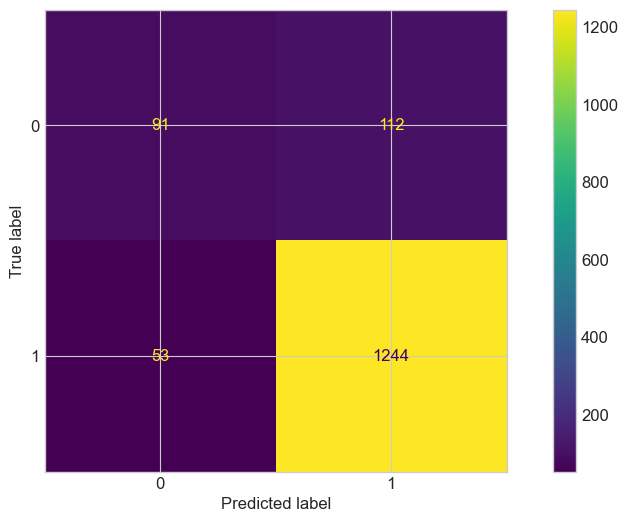

In [46]:
cnfmatrx = confusion_matrix(y_true=y_test, y_pred=pred,labels=model.classes_)

display = ConfusionMatrixDisplay(cnfmatrx, display_labels=[0,1])
display.plot()
plt.show()